In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler as SS

In [2]:
df = pd.read_csv('sales_data_sample.csv',encoding='latin1')
print(df.head())

   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

In [3]:
df.shape

(2823, 25)

In [4]:
int_columns = df.select_dtypes(include=['number']).columns.tolist()

In [5]:
print(int_columns)

['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'MSRP']


In [6]:
X = df[["QUANTITYORDERED","PRICEEACH","SALES","MSRP"]]

In [7]:
X.shape

(2823, 4)

In [8]:
sc = SS()
X_scaled = sc.fit_transform(X)

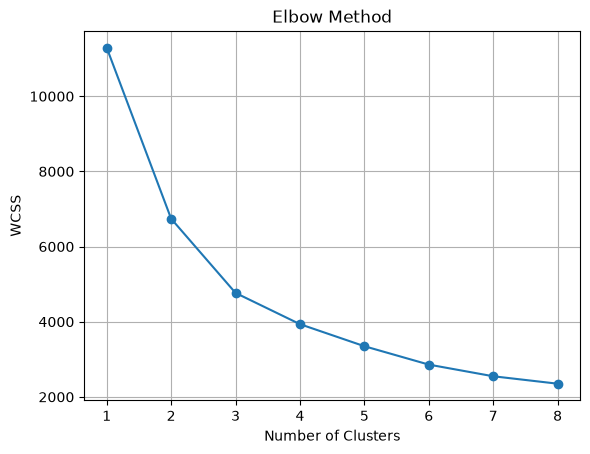

In [9]:
k1 = KMeans(n_clusters=1, random_state=42, n_init=10).fit(X_scaled)
k2 = KMeans(n_clusters=2, random_state=42, n_init=10).fit(X_scaled)
k3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled)
k4 = KMeans(n_clusters=4, random_state=42, n_init=10).fit(X_scaled)
k5 = KMeans(n_clusters=5, random_state=42, n_init=10).fit(X_scaled)
k6 = KMeans(n_clusters=6, random_state=42, n_init=10).fit(X_scaled)
k7 = KMeans(n_clusters=7, random_state=42, n_init=10).fit(X_scaled)
k8 = KMeans(n_clusters=8, random_state=42, n_init=10).fit(X_scaled)

wcss = [
    k1.inertia_, k2.inertia_, k3.inertia_, k4.inertia_,
    k5.inertia_, k6.inertia_, k7.inertia_, k8.inertia_
]

plt.plot(range(1, 9), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.xticks(range(1, 9))
plt.grid()
plt.show()

In [10]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

y_pred = kmeans.fit_predict(X_scaled)

# Display Cluster Counts
df['Cluster'] = y_pred

print("\nCluster Distribution:")
print(df['Cluster'].value_counts().sort_index())


Cluster Distribution:
Cluster
0    975
1    852
2    996
Name: count, dtype: int64


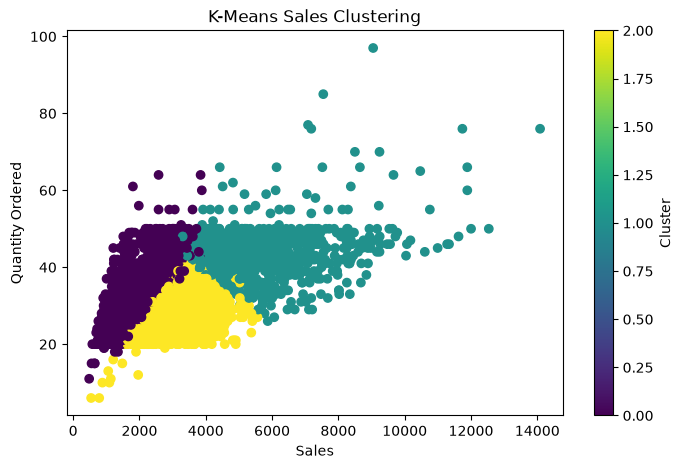

In [11]:
# 7. Visualize Clusters
plt.figure(figsize=(8, 5))

plt.scatter(df['SALES'], df['QUANTITYORDERED'],
            c=y_pred, cmap='viridis')

plt.xlabel("Sales")
plt.ylabel("Quantity Ordered")
plt.title("K-Means Sales Clustering")
plt.colorbar(label="Cluster")
plt.show()